In [1]:
base ="klue/bert-base"
# base = 'BM-K/KoSimCSE-bert'

In [2]:
from utils.preprocess import *
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(base)
temp = load_data_and_tokenize(tok, "./Text Classification Dataset/train.csv")
ds_train, ds_test = balanced_train_test_split(temp,ratio=0.3)
ds_test, ds_validation = balanced_train_test_split(ds_test,ratio=0.5)

In [3]:
import torch.nn as nn
from utils.models import *
from transformers import DataCollatorWithPadding

device = "cuda"
model = BertConv1dBinaryClassifier_MultiK(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)
optimizer = get_optimizer(model)
collator = DataCollatorWithPadding(tokenizer=tok)
num_epoch = 5 #1, 5

train_model(model, ds_train, ds_test, optimizer, collator, criterion, num_epochs=num_epoch)
# train_model(model, ds_train, ds_test, optimizer, collator, criterion, call_backs=[Save_best_model('temp'), Early_stop()])

epoch 1 end
train_loss: 0.1409534717201823
val_loss: 0.12624913454055786
epoch 2 end
train_loss: 0.11750351258004964
val_loss: 0.12439646571874619
epoch 3 end
train_loss: 0.10247007359204433
val_loss: 0.15110769867897034
epoch 4 end
train_loss: 0.0859370929228925
val_loss: 0.12487446516752243
epoch 5 end
train_loss: 0.06662792910052623
val_loss: 0.11727385967969894


In [11]:
#call_backs=[Save_best_model('temp'), Early_stop()] 쓰면은 가장 좋았던 모델을 불러와야 됨
# state_dict = torch.load('temp',map_location='cuda')
# model.load_state_dict(state_dict)

loss:0.12572111189365387
accuracy:0.9659737943335391
f1_score:0.7507537688442211


<Axes: xlabel='generated', ylabel='pred'>

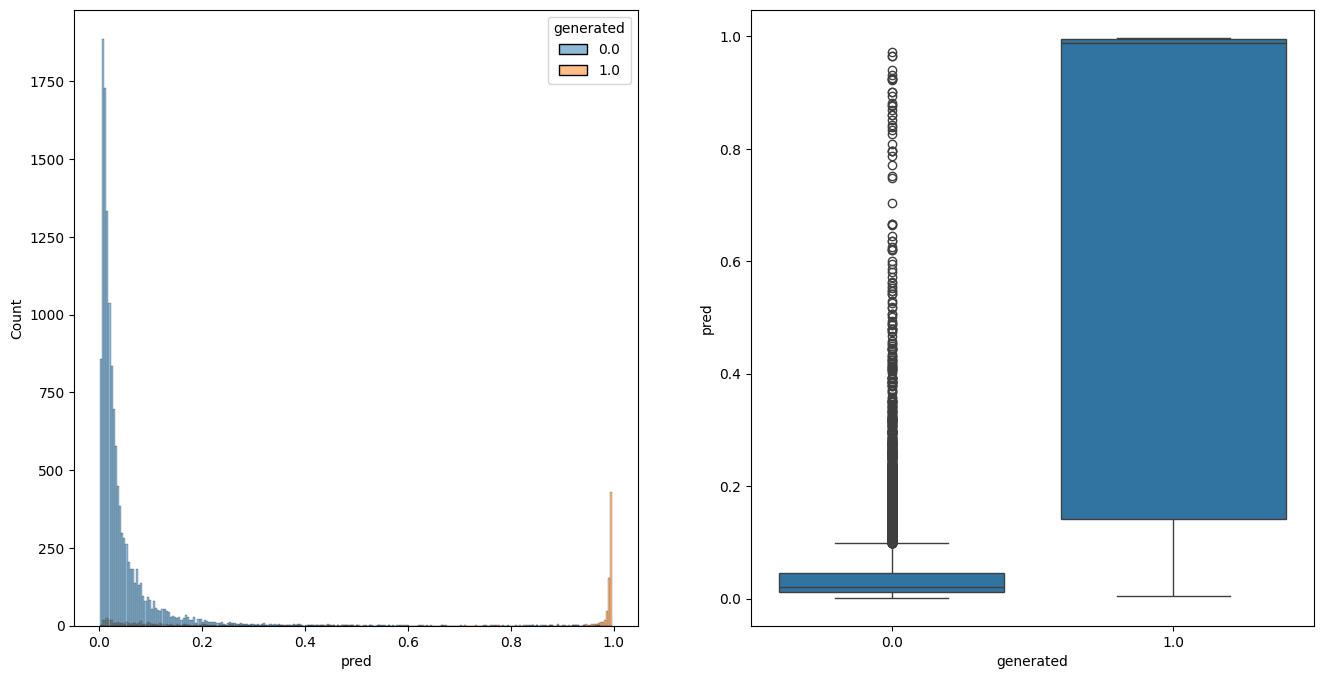

In [12]:
#1에폭일때
preds, targets = get_preds(model, ds_validation, collator)
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')
print(f'accuracy:{get_metric(preds, targets, 0.6, 'accuracy')}')
print(f'f1_score:{get_metric(preds, targets, 0.6, 'f1_score')}')

import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(16,8))
sns.histplot(ret, x='pred', hue='generated', ax=ax[0])
sns.boxplot(ret, x='generated', y='pred', ax=ax[1])

loss:0.10258027166128159
accuracy:0.971187487137271
f1_score:0.7935103244837758


<Axes: xlabel='generated', ylabel='pred'>

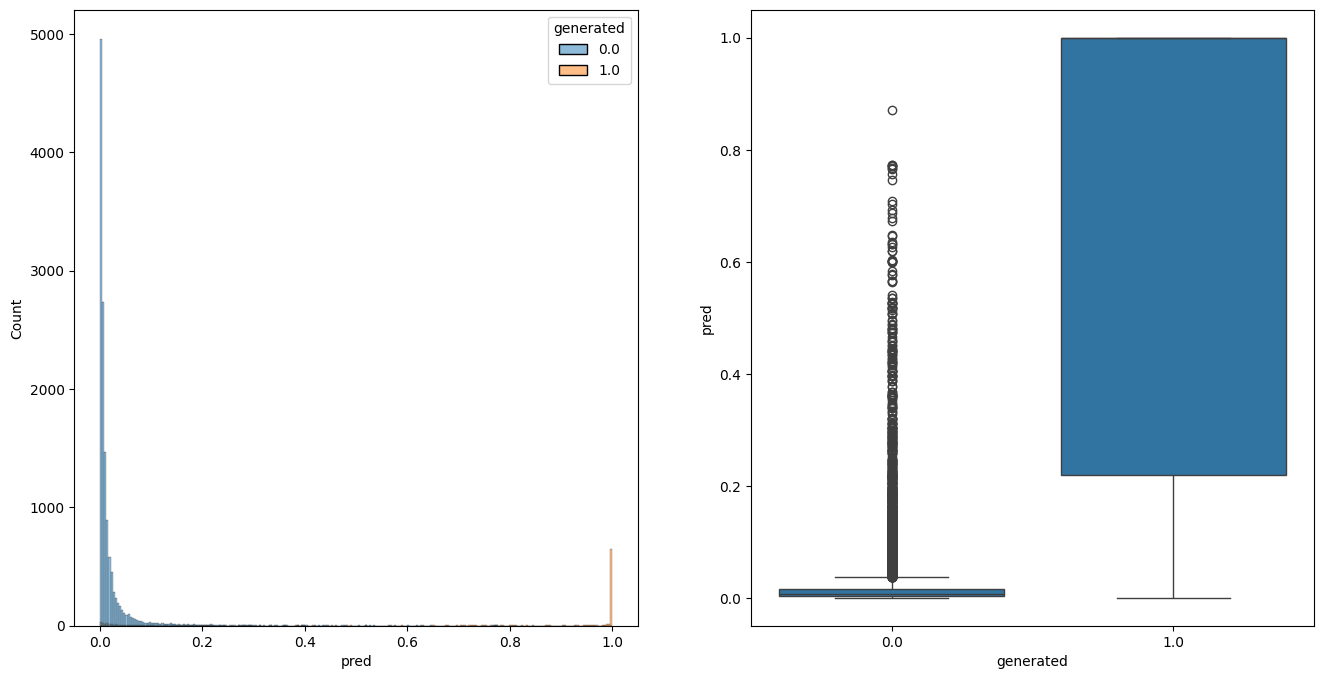

In [ ]:
#5에폭일때
preds, targets = get_preds(model, ds_validation, collator)
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')
print(f'accuracy:{get_metric(preds, targets, 0.6, 'accuracy')}')
print(f'f1_score:{get_metric(preds, targets, 0.6, 'f1_score')}')

import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(16,8))
sns.histplot(ret, x='pred', hue='generated', ax=ax[0])
sns.boxplot(ret, x='generated', y='pred', ax=ax[1])

ROC AUC: 0.9431545750168199
PR AUC (AP): 0.845519250186946


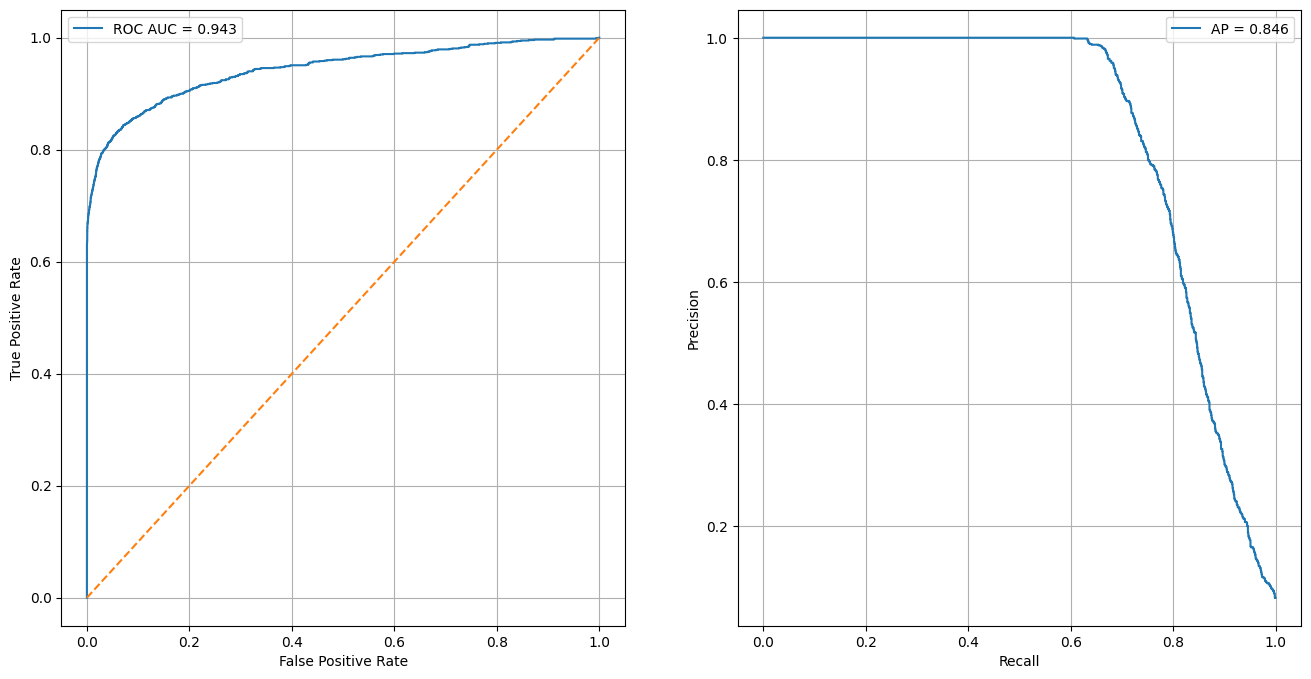

In [ ]:
'''
roc_auc:
    TPR= 실제 1 에서 1로 분류된 비율=recall : thres와 비례함
    FPR= 실제 0 에서 1로 분류된(잘못분류) 비율 : thres와 반비례함(아닌것도 다 맞다고 해버림), **불균형데이터에서는 높게나와버림(FPR=FP/TN+FP 에서 TN이 크므로)
    TPR과 FPR은 같이 커짐
    =>모델이 좋으면 0과 1을 잘 구분함=> TPR은 높고, FPR은 낮아야됨
rp_auc:
    recall(재현율)= TPR  : thres와 비례함,
    precision(정밀도)= 1로 분류한것중 실제 1의 비율 : thres와 반비례함, **TN**의 영향 안받음(precision=TP/TP+FP)
    recall이 낮으면 precision이 보통큼(1을 적게 고름=FP가 적음)
    =>**불균형 상황**에서모델이 좋으면 1이 적어도 1을 잘 찾아냄, 찾아낸것도 잘 맞음=> recall과 precision둘다 높아야됨
'''
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
auc_roc = roc_auc_score(targets, preds)
ap = average_precision_score(targets, preds)

print("ROC AUC:", auc_roc)
print("PR AUC (AP):", ap)

precision, recall, thresholds_roc = precision_recall_curve(targets, preds)
fpr, tpr, thresholds_rp = roc_curve(targets, preds)

fig, ax = plt.subplots(1,2,figsize=(16,8))

ax[0].plot(fpr, tpr, label=f"ROC AUC = {auc_roc:.3f}")
ax[0].plot([0, 1], [0, 1], "--")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(recall, precision, label=f"AP = {ap:.3f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend()
ax[1].grid(True)

In [4]:
# 저장
# torch.save(model.state_dict(), 'BertConv1dBinaryClassifier_MultiK_1epoch_20251205.pth')
torch.save(model.state_dict(), 'BertConv1dBinaryClassifier_MultiK_5epoch_20251205.pth')

In [ ]:
# 로딩
model_loaded = BertConv1dBinaryClassifier_MultiK(base)
model_loaded.to('cuda')
model_loaded.load_state_dict(torch.load('./model_savefiles/BertConv1dBinaryClassifier_MultiK_5epoch_20251205.pth',map_location='cuda'))

<All keys matched successfully>